****PRACTICA FINAL IA (YouTube Trending Videos)****

**Preprocesamiento**

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

Actualizamos la categoria de nuestro fichero csv en base a los datos que tenemos en el fichero JSON.

In [2]:
def actualizacion_categoria_pais(ruta_csv, ruta_json, nombre_pais):

    """Función que actualiza la category_id del Csv reemplazando por el valor string asignado en el fichero json y añade columna con el pais."""
    
    dfjson = pd.read_json(ruta_json)#en vez de leer linea por linea, empaqueta todo el json
    dfjson_aplanado = pd.json_normalize(dfjson['items'])
    dfjson_items = pd.DataFrame({'json_id': dfjson_aplanado['id'].astype(str),'category': dfjson_aplanado['snippet.title']})
    
    dfcsv = pd.read_csv(ruta_csv, encoding='utf-8', encoding_errors='replace')
    dfcsv['category_id'] = dfcsv['category_id'].astype(str)
    
    df_final = pd.merge(dfcsv, dfjson_items, left_on='category_id', right_on='json_id', how='left')
    
    df_final = df_final.drop(columns=['json_id', 'category_id'])

    df_final['pais'] = nombre_pais#creamos la columna pais 
                
    return df_final

In [3]:
paises = {"CA":"Canadá","DE":"Alemania","FR":"Francia","GB":"Gran Bretaña","IN":"India","JP":"Japón","KR":"Corea","MX":"Mexico","RU":"Rusia","US":"USA"}

In [4]:
dataframe_por_pais = (actualizacion_categoria_pais(f"{c}videos.csv", f"{c}_category_id.json", nombre) for c, nombre in paises.items())

Unificamos todos los dataframes

In [5]:
dataframe_final = pd.concat(dataframe_por_pais, ignore_index=True)

Confirmamos que en nuestro dataframe final hay registros de todos los paises.

In [6]:
dataframe_final.pais.value_counts()

pais
USA             40949
Canadá          40881
Alemania        40840
Rusia           40739
Francia         40724
Mexico          40451
Gran Bretaña    38916
India           37352
Corea           34567
Japón           20523
Name: count, dtype: int64

video_id: Identificador único del vídeo en YouTube.

trending_date: Fecha en la que el vídeo apareció en la lista de tendencias (formato año.día.mes).

title: El título del video en formato de texto original libre (tal y como lo escribió el creador, incluyendo emojis, mayúsculas y caracteres especiales). 

channel_title: El nombre original del canal de YouTube que subió el video.  

category_id: El identificador de la categoría asignada al video. Actualizado más arriba por el país en cuestión. 

publish_time: Fecha y hora en la que se publicó el vídeo.

tags: Las palabras clave asociadas al video. 

views: La cantidad de reproducciones acumuladas que registraba el video en ese día específico en que apareció en tendencias.  

likes: La cantidad de votos "Me gusta" acumulados que tenía el video en ese día específico.  

dislikes: La cantidad de votos "No me gusta" acumulados que tenía el video en ese día específico.  

comment_count: El número de comentarios totales escritos por los usuarios en ese día específico.  

thumbnail_link: Enlace a la imagen en miniatura del vídeo.

comments_disabled: Un interruptor lógico (True/False) que indica si el canal tenía los comentarios desactivados en ese momento.  

ratings_disabled: Un interruptor lógico (True/False) que indica si el canal tenía ocultos los contadores de likes/dislikes en ese momento.  

video_error_or_removed: Un interruptor lógico (True/False) que indica si el video fue borrado o tuvo un error mientras estaba en la lista de tendencias.  

description: El texto explicativo original largo que el creador colocó en la caja de descripción del video. 

pais: El país donde se obtuvo el dato.

In [7]:
dataframe_final.shape

(375942, 17)

Procedemos a quitar los duplicados.

In [8]:
dataframe_final.drop_duplicates(inplace=True)

In [9]:
dataframe_final.shape

(363372, 17)

Se eliminan alrededor de 12000 duplicados

Estos son los items que tendremos que predecir:  
1.Prediga la categoría del vídeo  
2.Predecir el número de likes  
3.Encontrar grupos en los vídeos mediante diversas técnicas de clusterización  
4.Crear un recomendador 

Las columnas video_id, description y thumbnail_link  no tiene ningún tipo de información que nos pueda ayudar. Las eliminamos.

In [10]:
dataframe_final.drop(["video_id", "thumbnail_link", "description"], axis=1, inplace=True)

In [11]:
dataframe_final.shape

(363372, 14)

In [12]:
dataframe_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 363372 entries, 0 to 375941
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   trending_date           363372 non-null  object
 1   title                   363372 non-null  object
 2   channel_title           363372 non-null  object
 3   publish_time            363372 non-null  object
 4   tags                    363372 non-null  object
 5   views                   363372 non-null  int64 
 6   likes                   363372 non-null  int64 
 7   dislikes                363372 non-null  int64 
 8   comment_count           363372 non-null  int64 
 9   comments_disabled       363372 non-null  bool  
 10  ratings_disabled        363372 non-null  bool  
 11  video_error_or_removed  363372 non-null  bool  
 12  category                360662 non-null  object
 13  pais                    363372 non-null  object
dtypes: bool(3), int64(4), object(7)
memory us

Vemos en category que hay algún nulo. Procedemos a eliminarlos

In [13]:
dataframe_final.dropna(inplace=True)

In [14]:
dataframe_final.shape

(360662, 14)

In [15]:
dataframe_final.info()#Confirmamos que se han quitado todos los nulos.

<class 'pandas.core.frame.DataFrame'>
Index: 360662 entries, 0 to 375941
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   trending_date           360662 non-null  object
 1   title                   360662 non-null  object
 2   channel_title           360662 non-null  object
 3   publish_time            360662 non-null  object
 4   tags                    360662 non-null  object
 5   views                   360662 non-null  int64 
 6   likes                   360662 non-null  int64 
 7   dislikes                360662 non-null  int64 
 8   comment_count           360662 non-null  int64 
 9   comments_disabled       360662 non-null  bool  
 10  ratings_disabled        360662 non-null  bool  
 11  video_error_or_removed  360662 non-null  bool  
 12  category                360662 non-null  object
 13  pais                    360662 non-null  object
dtypes: bool(3), int64(4), object(7)
memory us

Vamos con title y channel title. Vemos que es un video de tendencias por lo que podria suceder que el mismo video fuera tendencia varios dias 
y por tantos los datos pudieran estar duplicados pero el drop_duplicates no haya funcionado porque las variables numéricas sean diferentes.

In [16]:
df_duplicados_ejemplos = dataframe_final[dataframe_final.duplicated(subset=["title", "channel_title"])]#keep false para valores unicos sin repetir duplicados
df_duplicados_ejemplos.head(5)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais
200,17.15.11,PLUSH - Bad Unboxing Fan Mail,iDubbbzTV,2017-11-13T17:00:00.000Z,"plush|""bad unboxing""|""unboxing""|""fan mail""|""id...",2649977,193479,3496,17846,False,False,False,Comedy,Canadá
214,17.15.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",20539417,840642,47715,124236,False,False,False,Music,Canadá
216,17.15.11,STRANGER JOKES : Jokes de Papa avec les teens ...,"Le Jeu, C'est Sérieux",2017-11-13T15:48:57.000Z,"Stranger Jokes|""Jokes de Papa""|""Stranger Thing...",443131,27026,491,746,False,False,False,Comedy,Canadá
218,17.15.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,2017-11-13T17:13:01.000Z,SHANtell martin,2188675,88100,7150,24225,False,False,False,People & Blogs,Canadá
219,17.15.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",4326684,167696,6730,9265,False,False,False,Comedy,Canadá


Los registros que nos aparecen son registros que tienen más de un registro con el mismo nombre y canal. Veamos un ejemplo:

In [17]:
df_ejemplo_especifico = dataframe_final[(dataframe_final["title"] == "Eminem - Walk On Water (Audio) ft. Beyoncé") & (dataframe_final["channel_title"] == "EminemVEVO")]
df_ejemplo_especifico.head(5)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais
0,17.14.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787425,43420,125882,False,False,False,Music,Canadá
214,17.15.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",20539417,840642,47715,124236,False,False,False,Music,Canadá
498,17.16.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",22702386,869304,50018,123235,False,False,False,Music,Canadá
791,17.17.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",24578152,891283,51978,125444,False,False,False,Music,Canadá
40917,17.14.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787424,43420,125882,False,False,False,Music,Alemania


Vemos que hay columnas repetidas en las que como pasa aquí fue trending en varias ocasiones. Haremos filtrado y dejaremos un valor único por país teniendo en cuenta principalmente la variable views, ya que a priori a mas alta dicha variable mas likes, dislikes y commments debería haber ya que el formato youtube va acumulando cada dia dichos items. Tenemos en cuenta país ya que un mismo vídeo puede ser tendencia en dos o más países y de cara a nuestro modelo puede ser interesante.

In [18]:
dataframe_final["trending_date"] = pd.to_datetime(dataframe_final["trending_date"], format="%y.%d.%m", errors="coerce").dt.floor('D')
dataframe_final["primer_trending"] = dataframe_final.groupby(["channel_title", "title", "pais"])["trending_date"].transform("min")#primer día en tendencias de cada vídeo en cada país

dataframe_final.sort_values(by="views", ascending=False, inplace=True)

dataframe_final.drop_duplicates(subset=["channel_title", "title", "pais"],keep="first",inplace=True)

Una vez ordenados los datos y quitados los duplicados, confirmamos que efectivamente nos ha dejado un valor único por país y si habiendo varios regitros iguales el que más views tiene (ver Canadá por ejemplo)

In [19]:
df_ejemplo_especifico = dataframe_final[(dataframe_final["title"] == "Eminem - Walk On Water (Audio) ft. Beyoncé") & (dataframe_final["channel_title"] == "EminemVEVO")]
df_ejemplo_especifico.head(10)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais,primer_trending
125227,2017-11-27,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",39235314,1044324,63815,137383,False,False,False,Music,Gran Bretaña,2017-11-14
335988,2017-11-18,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",26448434,911883,53873,127481,False,False,False,Music,USA,2017-11-14
791,2017-11-17,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",24578152,891283,51978,125444,False,False,False,Music,Canadá,2017-11-14
40917,2017-11-14,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787424,43420,125882,False,False,False,Music,Alemania,2017-11-14
81791,2017-11-14,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem""|""Walk""|""On""|""Water""|""Aftermath/Shady/I...",17158579,787425,43420,125882,False,False,False,Music,Francia,2017-11-14
219394,2017-11-14,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787426,43420,125882,False,False,False,Music,Corea,2017-11-14


In [20]:
dataframe_final.shape#Aligeramos el peso del dataframe.

(207525, 15)

In [21]:
dataframe_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 207525 entries, 150857 to 314568
Data columns (total 15 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   trending_date           207525 non-null  datetime64[ns]
 1   title                   207525 non-null  object        
 2   channel_title           207525 non-null  object        
 3   publish_time            207525 non-null  object        
 4   tags                    207525 non-null  object        
 5   views                   207525 non-null  int64         
 6   likes                   207525 non-null  int64         
 7   dislikes                207525 non-null  int64         
 8   comment_count           207525 non-null  int64         
 9   comments_disabled       207525 non-null  bool          
 10  ratings_disabled        207525 non-null  bool          
 11  video_error_or_removed  207525 non-null  bool          
 12  category                207525

Procedemos a pasar publish time a formato datetime y creamos una columna que indica los números de días que pasaron desde que se publicó hasta que fue tendencia por primera vez en cada país. Para ello, antes de quitar los duplicados, guardamos la primera fecha en la que cada vídeo apareció en tendencias. Una vez se ha creado la columna, eliminamos las columnas de fechas.

In [22]:
dataframe_final["publish_time"] = pd.to_datetime(dataframe_final["publish_time"], errors="coerce").dt.tz_localize(None).dt.floor('D')


dataframe_final["dias_desde_publicacion"] = (dataframe_final["primer_trending"] - dataframe_final["publish_time"]).dt.days.clip(lower=0)



In [23]:
dataframe_final.drop(["trending_date","publish_time","primer_trending"], axis=1, inplace=True)

In [24]:
dataframe_final.head(5)

,title,channel_title,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais,dias_desde_publicacion
150857,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,"Bad Bunny|""Amorfoda""|""Dura""|""Daddy Yankee""|""Oz...",424538912,2818771,149275,99380,False,False,False,Music,Gran Bretaña,2
156905,"Te Bote Remix - Casper, Nio García, Darell, Ni...",Flow La Movie,"Te Bote|""Te Bote Remix""|""Flow La Movie""|""Ozuna...",337621571,2581961,166549,113564,False,False,False,Music,Gran Bretaña,3
147990,Bad Bunny - Amorfoda | Video Oficial,Bad Bunny,"Bad|""Bunny""|""Bad Bunny""|""Video Oficial""|""Music...",328860380,3823879,215530,225216,False,False,False,Music,Gran Bretaña,1
143607,Ozuna x Romeo Santos - El Farsante Remix,Ozuna,"Ozuna|""Reggaeton""|""Odisea""|""Odisea The Album""|...",288811992,1618180,151147,67506,False,False,False,Music,Gran Bretaña,2
160846,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,"Childish Gambino|""Rap""|""This Is America""|""mcDJ...",259721696,5444541,379862,553371,False,False,False,Music,Gran Bretaña,1


Vamos a modificar los formatos de cada columna. Comenzaremos con title de tipo string. Procedemos a quitar los espacios 
y los posibles saltos de línea al introducir el nombre del title.

In [25]:
dataframe_final["title"] = (dataframe_final["title"].str.strip().str.split().str.join(" "))

Realizamos la misma transformación en channel_title:

In [26]:
dataframe_final["channel_title"] = (dataframe_final["channel_title"].str.strip().str.split().str.join(" "))

En el caso de tags además de los espacios en blanco, debemos de quitar "|" para que el modelo pueda leerlo mejor. 
Metemos los datos en una lista.

In [27]:
dataframe_final["tags"] = (dataframe_final["tags"].str.strip().str.split().str.join(" "))
dataframe_final["tags"] = dataframe_final["tags"].str.replace('"', '', regex=False)#regex=False: busca el texto tal cual, sin tratarlo como expresión regular
dataframe_final["tags"] = dataframe_final["tags"].str.replace('[none]', '', regex=False)
dataframe_final["tags"] = (dataframe_final["tags"].str.strip().str.split("|", regex=False))
dataframe_final["tags"] = dataframe_final["tags"].apply(lambda lista: [tag for tag in lista if tag != ""])#quitamos las etiquetas vacías

In [28]:
dataframe_final.head(5)

,title,channel_title,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais,dias_desde_publicacion
150857,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,"[Bad Bunny, Amorfoda, Dura, Daddy Yankee, Ozun...",424538912,2818771,149275,99380,False,False,False,Music,Gran Bretaña,2
156905,"Te Bote Remix - Casper, Nio García, Darell, Ni...",Flow La Movie,"[Te Bote, Te Bote Remix, Flow La Movie, Ozuna,...",337621571,2581961,166549,113564,False,False,False,Music,Gran Bretaña,3
147990,Bad Bunny - Amorfoda | Video Oficial,Bad Bunny,"[Bad, Bunny, Bad Bunny, Video Oficial, Music V...",328860380,3823879,215530,225216,False,False,False,Music,Gran Bretaña,1
143607,Ozuna x Romeo Santos - El Farsante Remix,Ozuna,"[Ozuna, Reggaeton, Odisea, Odisea The Album, R...",288811992,1618180,151147,67506,False,False,False,Music,Gran Bretaña,2
160846,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,"[Childish Gambino, Rap, This Is America, mcDJ ...",259721696,5444541,379862,553371,False,False,False,Music,Gran Bretaña,1


Limpio el dataset, lo guardamos en formato pickle y  pasamos al análisis exploratorio

In [29]:
dataframe_final.to_pickle("dataframe_final_limpio.pkl")

**Analisis exploratorio**

A continuación vamos a ver un poco los datos que tenemos después de procesar nuestro df. Para ello cargamos el dataset limpio que hemos guardado en formato pickle.

In [30]:
df = pd.read_pickle("dataframe_final_limpio.pkl")

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 207525 entries, 150857 to 314568
Data columns (total 13 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   title                   207525 non-null  object
 1   channel_title           207525 non-null  object
 2   tags                    207525 non-null  object
 3   views                   207525 non-null  int64 
 4   likes                   207525 non-null  int64 
 5   dislikes                207525 non-null  int64 
 6   comment_count           207525 non-null  int64 
 7   comments_disabled       207525 non-null  bool  
 8   ratings_disabled        207525 non-null  bool  
 9   video_error_or_removed  207525 non-null  bool  
 10  category                207525 non-null  object
 11  pais                    207525 non-null  object
 12  dias_desde_publicacion  207525 non-null  int64 
dtypes: bool(3), int64(5), object(5)
memory usage: 18.0+ MB


In [32]:
matriz_correlacion = df.corr(numeric_only=True)#sacamos la matriz de correlacion para vaer relacion de las variables numéricas

In [33]:
print(matriz_correlacion)

                           views     likes  dislikes  comment_count  \
views                   1.000000  0.747095  0.442746       0.528759   
likes                   0.747095  1.000000  0.429676       0.803652   
dislikes                0.442746  0.429676  1.000000       0.637617   
comment_count           0.528759  0.803652  0.637617       1.000000   
comments_disabled      -0.006558 -0.022285 -0.006149      -0.022113   
ratings_disabled       -0.011216 -0.027856 -0.011366      -0.015297   
video_error_or_removed  0.006401  0.007036  0.002517       0.003513   
dias_desde_publicacion -0.002717 -0.005195 -0.002071      -0.004165   

                        comments_disabled  ratings_disabled  \
views                           -0.006558         -0.011216   
likes                           -0.022285         -0.027856   
dislikes                        -0.006149         -0.011366   
comment_count                   -0.022113         -0.015297   
comments_disabled                1.000000    

Conclusiones:  

Likes y comment_count: Si hay un like, suele haber un comentario de manera generalizada.

Views y likes: A más visualizaciones más likes. Por lo tanto views, likes y comment_count suelen ir de la mano.

Dislikes con views, likes y comment_count: Cuanto más se ve el video, más posibles dislikes puede provocar y por tanto, mas comentarios a modo de hate.

In [34]:
df.describe()

,views,likes,dislikes,comment_count,dias_desde_publicacion
count,2.075250e+05,2.075250e+05,2.075250e+05,2.075250e+05,207525.000000
mean,5.340433e+05,1.626300e+04,9.406069e+02,2.005660e+03,3.266994
std,3.279155e+06,8.822365e+04,1.250509e+04,1.409846e+04,62.288545
min,1.530000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,2.581900e+04,3.750000e+02,2.300000e+01,6.000000e+01,1.000000
50%,9.312400e+04,1.732000e+03,9.400000e+01,2.710000e+02,1.000000
75%,3.247840e+05,7.470000e+03,3.720000e+02,1.041000e+03,1.000000
max,4.245389e+08,5.613827e+06,1.944971e+06,1.626501e+06,4215.000000


Podemos ver que los valores máximos y minimos distorsionan mucho con respecto a la media y si intentamos sacar outliers, vemos 
que hay en las variables views, likes, dislikes, comment_count y dias desde publicación. Esto es debido a la viralidad que se puede dar con cierto vídeo. Vamos a representar los outliers de views ya que como vimos anteriormente a partir de ella el resto de outliers que hemos visto también pueden aumentar dada su gran relación.

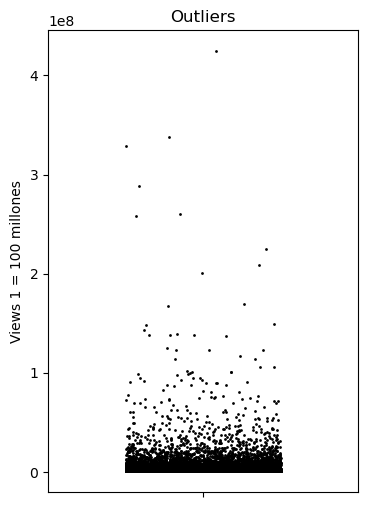

In [35]:
Q1 = df["views"].quantile(0.25)
Q3 = df["views"].quantile(0.75)
IQR = Q3 - Q1 #Rango intercuantílico
limite_outliers = Q3 + (1.5 * IQR)
df_outliers = df[df["views"] > limite_outliers]

plt.figure(figsize=(4, 6))
sns.stripplot(y=df_outliers["views"], color="black", jitter=0.25,size=2)

plt.title("Outliers")
plt.ylabel("Views 1 = 100 millones")
plt.show()

Vemos claramente los outliers y de cara al EDA los dejamos ya que según que planteamiento puede ser bueno quitarlos o no.

**Analisis univariado de variables categoricas**

In [36]:
df.category.value_counts(normalize=True)

category
Entertainment            0.295540
People & Blogs           0.172495
News & Politics          0.114208
Sports                   0.075157
Music                    0.067139
Comedy                   0.063496
Film & Animation         0.052818
Howto & Style            0.051295
Gaming                   0.029828
Education                0.021183
Science & Technology     0.019718
Autos & Vehicles         0.016894
Pets & Animals           0.012191
Travel & Events          0.004563
Shows                    0.003315
Nonprofits & Activism    0.000072
Movies                   0.000072
Trailers                 0.000014
Name: proportion, dtype: float64

Vemos que más de la mitad de los videos son de la categoría Entertainment, People & Blogs y News & Politics.

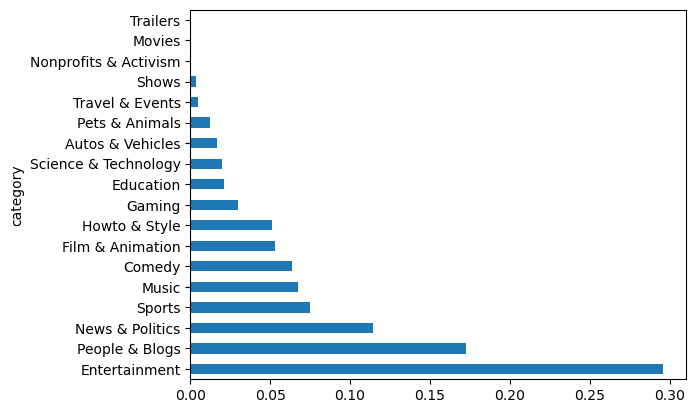

In [37]:
df.category.value_counts(normalize=True).plot.barh()
plt.show()

Vemos que las categorías Trailers, Movies y Nonprofits & Activism tienen muy pocos registros

In [38]:
df.category.value_counts()[["Trailers", "Movies", "Nonprofits & Activism"]]

category
Trailers                  3
Movies                   15
Nonprofits & Activism    15
Name: count, dtype: int64

Procedemos a eliminarlas ya que, con tan pocos vídeos, quitan más de lo que aportan a los modelos.

In [39]:
df.drop(df[df["category"].isin(["Trailers", "Movies", "Nonprofits & Activism"])].index, inplace=True)

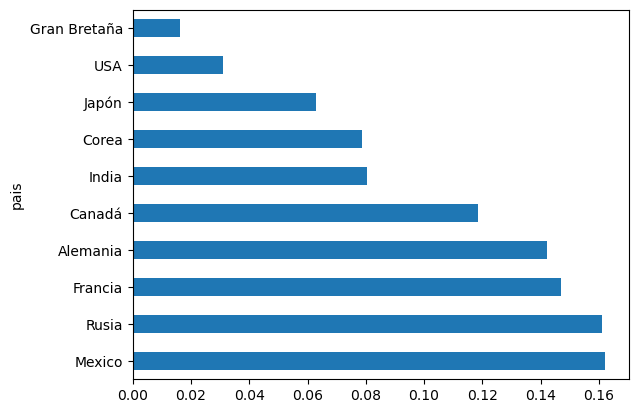

In [40]:
df.pais.value_counts(normalize=True).plot.barh()
plt.show()

Vemos que lo datos se centran sobre todo en los paises Rusia, Mexico, Alemania, Francia y Canada

In [41]:
df['comments_disabled'].value_counts()

comments_disabled
False    202599
True       4893
Name: count, dtype: int64

In [42]:
df['ratings_disabled'].value_counts()

ratings_disabled
False    202860
True       4632
Name: count, dtype: int64

In [43]:
df['video_error_or_removed'].value_counts()

video_error_or_removed
False    207387
True        105
Name: count, dtype: int64

In [44]:
df.drop('video_error_or_removed', axis=1, inplace=True)

Vemos que no tiene ningún valor esta variable por lo que la eliminamos ahora aquí e insertamos la actualización el fichero preprocess.

In [45]:
df.sort_values(by='views', ascending=False).head(10)

,title,channel_title,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,category,pais,dias_desde_publicacion
150857,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,"[Bad Bunny, Amorfoda, Dura, Daddy Yankee, Ozun...",424538912,2818771,149275,99380,False,False,Music,Gran Bretaña,2
156905,"Te Bote Remix - Casper, Nio García, Darell, Ni...",Flow La Movie,"[Te Bote, Te Bote Remix, Flow La Movie, Ozuna,...",337621571,2581961,166549,113564,False,False,Music,Gran Bretaña,3
147990,Bad Bunny - Amorfoda | Video Oficial,Bad Bunny,"[Bad, Bunny, Bad Bunny, Video Oficial, Music V...",328860380,3823879,215530,225216,False,False,Music,Gran Bretaña,1
143607,Ozuna x Romeo Santos - El Farsante Remix,Ozuna,"[Ozuna, Reggaeton, Odisea, Odisea The Album, R...",288811992,1618180,151147,67506,False,False,Music,Gran Bretaña,2
160846,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,"[Childish Gambino, Rap, This Is America, mcDJ ...",259721696,5444541,379862,553371,False,False,Music,Gran Bretaña,1
148381,Drake - God’s Plan,DrakeVEVO,"[Drake new music, Drake Gods Plan, Drake God’s...",258164991,4737873,117198,301756,False,False,Music,Gran Bretaña,5
373540,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,"[Childish Gambino, Rap, This Is America, mcDJ ...",225211923,5023450,343541,517232,False,False,Music,USA,2
158165,Ariana Grande - No Tears Left To Cry,ArianaGrandeVevo,"[Ariana, Grande, No, Tears, Left, To, Cry, Uni...",208876887,3394437,150086,259613,False,False,Music,Gran Bretaña,1
158168,"Becky G, Natti Natasha - Sin Pijama (Official ...",BeckyGVEVO,"[Becky G, Natti Natasha, Natti Natasha Music, ...",200862743,1668418,142569,97826,False,False,Music,Gran Bretaña,16
130634,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,"[Rewind, Rewind 2017, youtube rewind 2017, #Yo...",169884583,3312868,1753274,845233,False,False,Entertainment,Gran Bretaña,1


Vemos que hay videos que han sido tendencia en diferentes países.

**Analisis multivariado**

In [46]:
df.pivot_table(index="pais", columns="category", values="views")

category,Autos & Vehicles,Comedy,Education,Entertainment,Film & Animation,Gaming,Howto & Style,Music,News & Politics,People & Blogs,Pets & Animals,Science & Technology,Shows,Sports,Travel & Events
pais,,,,,,,,,,,,,,,
Alemania,1.934430e+05,6.370840e+05,144247.965465,4.317013e+05,5.769994e+05,3.500935e+05,299676.137482,2.024636e+06,251877.822710,3.046419e+05,2.919468e+05,4.782260e+05,4.761774e+05,5.810094e+05,1.406850e+05
Canadá,4.816398e+05,8.724318e+05,459409.744538,7.317288e+05,9.819128e+05,7.185641e+05,663049.498428,3.167182e+06,307902.629232,5.765851e+05,5.519081e+05,9.654540e+05,5.817826e+05,8.038909e+05,3.963594e+05
Corea,1.070090e+05,3.513303e+05,118163.835443,4.361690e+05,4.645750e+05,2.492368e+05,382025.701887,1.774032e+06,134716.433151,1.941641e+05,1.925386e+05,2.568550e+06,1.082023e+05,6.916621e+05,2.669650e+05
Francia,6.090521e+04,3.730210e+05,129644.401421,3.449008e+05,3.556891e+05,2.414941e+05,182430.649468,1.144151e+06,117205.640959,1.904643e+05,1.643618e+05,4.041146e+05,5.236306e+05,4.004828e+05,5.457332e+04
Gran Bretaña,1.457632e+06,1.967056e+06,780772.000000,2.567087e+06,2.427073e+06,8.232446e+05,459653.915000,1.272255e+07,773944.250000,1.245253e+06,8.816329e+05,1.993358e+06,1.709880e+06,1.040113e+06,1.071762e+06
India,3.332654e+05,7.089324e+05,92438.020910,5.766691e+05,1.778204e+06,3.227187e+06,822677.317427,2.076332e+06,297426.506202,4.474413e+05,1.317532e+06,6.594729e+05,6.513166e+05,1.410399e+06,1.929078e+05
Japón,6.246815e+04,3.672608e+05,83620.590361,2.504836e+05,2.547108e+05,1.487873e+05,116843.424184,6.492050e+05,118175.592513,1.264726e+05,4.913599e+04,8.949333e+05,NaN,2.668928e+05,1.111057e+05
Mexico,1.372178e+05,4.076255e+05,78476.971014,2.464302e+05,3.091245e+05,3.692244e+05,164914.949683,9.706897e+05,138016.199127,1.275828e+05,4.638445e+05,2.927205e+05,2.181200e+04,3.248669e+05,1.348224e+05
Rusia,2.097492e+05,2.889580e+05,53657.478064,3.157302e+05,1.625047e+05,1.926100e+05,168871.154684,7.699724e+05,118024.212121,1.247756e+05,9.047947e+04,3.244303e+05,1.773477e+05,1.886925e+05,7.596964e+04


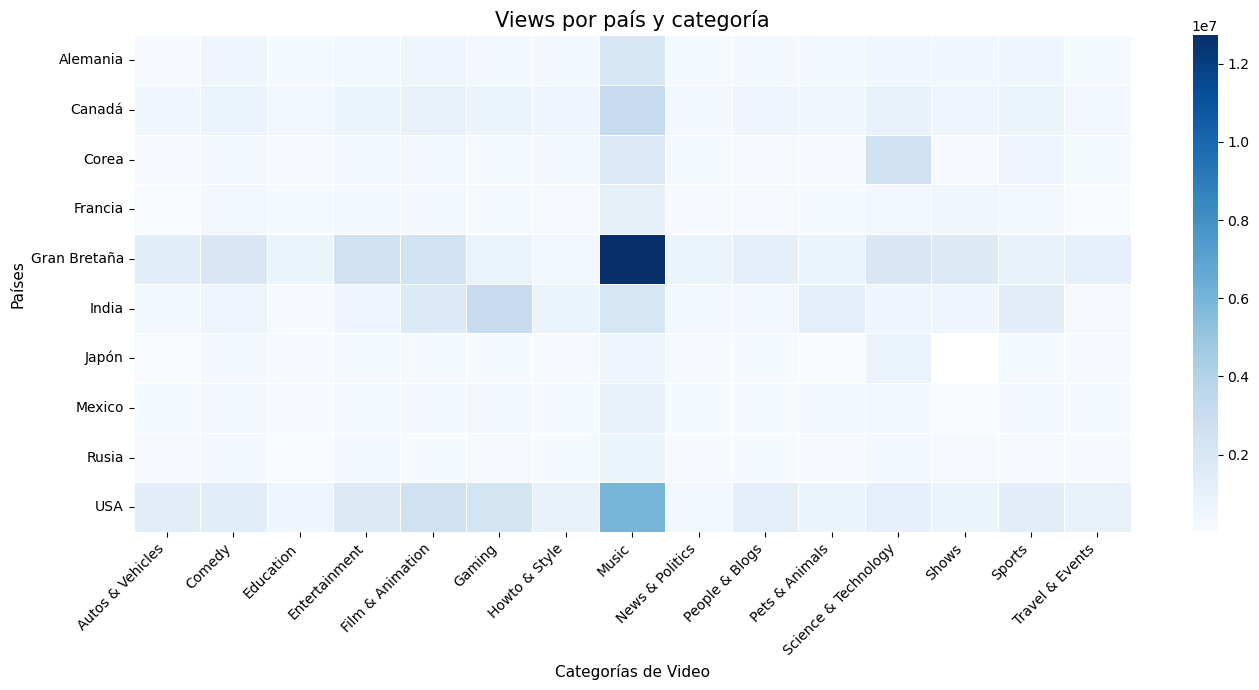

In [47]:
pivot_views = df.pivot_table(index="pais", columns="category", values="views")
plt.figure(figsize=(14, 7))

sns.heatmap(pivot_views, cmap="Blues", annot=False, linewidths=0.5)

plt.title("Views por país y categoría",fontsize=15)
plt.xlabel("Categorías de Video", fontsize=11)
plt.ylabel("Países", fontsize=11)
plt.xticks(rotation=45, ha="right") 

plt.tight_layout()
plt.show()

Vemos que las mayorias de visualizaciones se dan en Gran Bretaña y EEUU y que la categoría que más views suele tener es Music. El hecho de que un video sea de Gran Bretaña y de Musica puede ser relevante por ejemplo para el modelo, por lo que ambas categorías es bueno tenerlas en cuenta.

Vamos a desglosar comments_disabled	y ratings_disable. Estas dos variables la mayoría del tiempo son False ya que lo normal es querer que la gente comente y haga like o dislike a tus videos. Vamos a ver en cuantos casos desactivaron ambas variables.

In [48]:
Desactivadas = df[(df["comments_disabled"] == True) & (df["ratings_disabled"] == True)]

In [49]:
Desactivadas.shape

(1421, 12)

In [50]:
Desactivadas = df[(df["comments_disabled"] == True) & (df["ratings_disabled"] == True)]
Activadas = df[(df["comments_disabled"] == False) & (df["ratings_disabled"] == False)]

promedio_desactivadas = Desactivadas[["views"]].mean()# Calculamos el promedio de views para ambos grupos
promedio_activadas = Activadas[["views"]].mean()

# Juntamos ambos resultados en una pequeña tabla para compararlos
comparativa_directa = pd.DataFrame({"Ambas Activadas": promedio_activadas, "Ambas Desactivadas": promedio_desactivadas}).T #Transponemos para que se cambien columnas y filas

print(comparativa_directa)

                            views
Ambas Activadas     542451.836745
Ambas Desactivadas  466464.339901


Vemos que cuando los comentarios y los ratings están deshabilitados, los vídeos tienen menos visualizaciones de media (466.464 frente a 542.452). Si usamos la mediana, que es más robusta frente a los outliers que vimos antes, la diferencia es aún mayor: 26.352 views frente a 95.433, unas 3,6 veces menos.

Una posible explicación es que el algoritmo de YouTube da más visibilidad a los vídeos que generan interacción (likes, dislikes y comentarios). Si el creador desactiva esas interacciones, el vídeo pierde señales de engagement y es menos recomendado. Además, este tipo de vídeos suele ser de nicho: canales de noticias o institucionales que evitan polémicas, contenido infantil o canales que prefieren no moderar comentarios. De hecho, entre los vídeos con ambas opciones desactivadas tiene más peso News & Politics (casi un 20 %) y destacan países como Japón, Francia e India.

Vimos que de media los videos suelen tardar unos 3 días en ser tendencia, aunque la mediana nos indica que suelen tardar alrededor de 1 dia. La dispersión es grande y se puede ver porque por ejemplo el vídeo máximo tardo 4215 dias en ser tendencia algo poco común.

Las conclusiones que podemos sacar son las siguientes:
1. Existe una relación clara entre los views, los coments y los likes/dislikes.
2. Entertainment, People & Blogs y News & Politics son las categorías que más destacan.
3. Un mismo vídeo puede ser viral en varios países.
4. Los vídeos con los comentarios y los ratings desactivados tienen menos visualizaciones (la mediana es unas 3,6 veces menor), probablemente porque al no generar interacción el algoritmo los recomienda menos.
5. Cruzando datos vemos que los videos que más views han tenido son de Musica fundamentalmente en Reino Unido. Tanto Reino Unido como el tipo Musica muestran ser una de las piezas fundamentales sobre las que giran las visualizaciones.

A continuación vamos a pasar a realizar punto por punto lo solicitado en los modelos.

**Predecir categoria del video**

Vamos a utilizar los modelos conocidos de scikit-learn sobre el dataset limpio que cargamos desde el fichero pickle.

In [51]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder,FunctionTransformer
from sklearn.compose import ColumnTransformer #lo usamo para ensamblar
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

Incluimos comment_count junto al resto de variables numéricas. No incluimos comments_disabled ni ratings_disabled porque son casi siempre False y apenas aportan información al modelo.

In [52]:
X = df[["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion", "pais"]]
y = df["category"]

In [53]:
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)#conserva proporcion entre particiones

In [54]:
le = LabelEncoder()
le.fit(ytrain)
ytrain = le.transform(ytrain)
ytest = le.transform(ytest)

In [55]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
#Definimos el encoder para las variables que sean categoricas, en este caso solo será pais.

In [56]:
logaritmo = FunctionTransformer(np.log1p)
scaler = StandardScaler()
#Definimos las transformaciones numéricas para tratar los outliers

Regresión logística

In [57]:
from sklearn.linear_model import LogisticRegression

In [58]:
lr = LogisticRegression(max_iter=1000)#subimos las iteraciones porque con las 100 por defecto el modelo no terminaba de ajustarse

Creamos un pipeline numérico para incluirlo en el ensamblador de Column Transformer ya que según el modelo los outliers pueden o no ser relevantes de quitar.

In [59]:
pipeline_num = Pipeline([('log', logaritmo),('scaler', scaler)])

In [60]:
preprocess_lr = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais"]),
    ("num_procesadas", pipeline_num, ["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion"])])

In [61]:
pipeline_lr = Pipeline(steps=[('preprocesamiento', preprocess_lr),
                              ('modelo', lr)])

In [62]:
pipeline_lr.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['pais']),
                                                 ('num_procesadas',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['views', 'likes', 'dislikes',
                                                   'comment_count',
                                                   'dias_desde_publicacion'])])),
                ('modelo', LogisticRegression(max_iter=1000))])

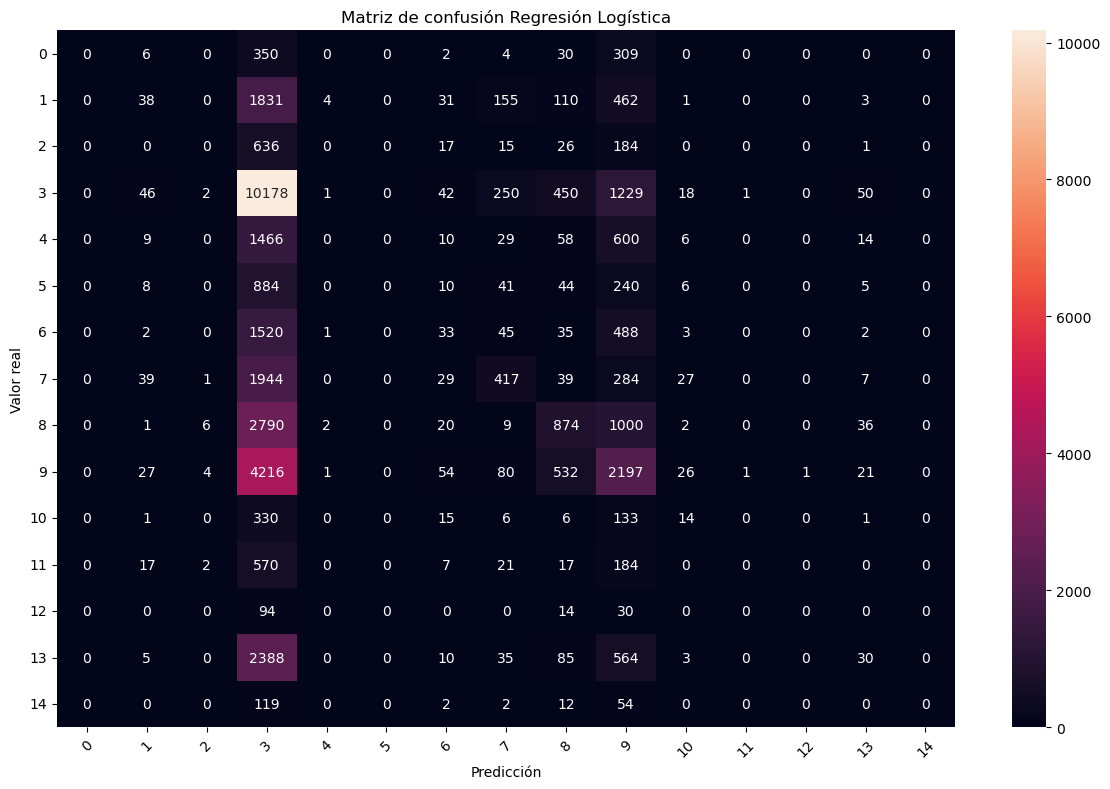

In [63]:
#Matriz confusión regresión logística.

y_pred_lr = pipeline_lr.predict(Xtest)

cm = confusion_matrix(ytest, y_pred_lr)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,          # muestra los valores dentro de cada celda
    fmt="d",            # formato entero
    cbar=True           # barra de color
)
plt.title("Matriz de confusión Regresión Logística")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Vemos en la matriz que el modelo está muy descompensado hacia las clases 3 y 9. Es posible que haya un desbalanceo en el cual haya clases más dominantes y clases con menos registros y por ello, el modelo tienda a no predecir nunca las no dominantes. Lo podemos ver a continuación.

In [64]:
df["category"].value_counts()

category
Entertainment           61332
People & Blogs          35797
News & Politics         23701
Sports                  15597
Music                   13933
Comedy                  13177
Film & Animation        10961
Howto & Style           10645
Gaming                   6190
Education                4396
Science & Technology     4092
Autos & Vehicles         3506
Pets & Animals           2530
Travel & Events           947
Shows                     688
Name: count, dtype: int64

Random Forest

En Random Forest no es necesario tratar los outliers ni escalar las variables, ya que los árboles dividen los datos por umbrales y no les afecta la magnitud de los valores. Por tanto, dejamos las variables numéricas tal cual.

In [65]:
from sklearn.ensemble import RandomForestClassifier

In [66]:
rf = RandomForestClassifier()

In [67]:
preprocess_rf = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais"]),
    ("numericas", "passthrough",
     ["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion"])#ponemos esto ya que con column transformer hay que incluirlas aunque no les hagamos nada.
])

In [68]:
pipeline_rf = Pipeline(steps=[('preprocesamiento', preprocess_rf),
                              ('modelo', rf)])

In [69]:
pipeline_rf.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['pais']),
                                                 ('numericas', 'passthrough',
                                                  ['views', 'likes', 'dislikes',
                                                   'comment_count',
                                                   'dias_desde_publicacion'])])),
                ('modelo', RandomForestClassifier())])

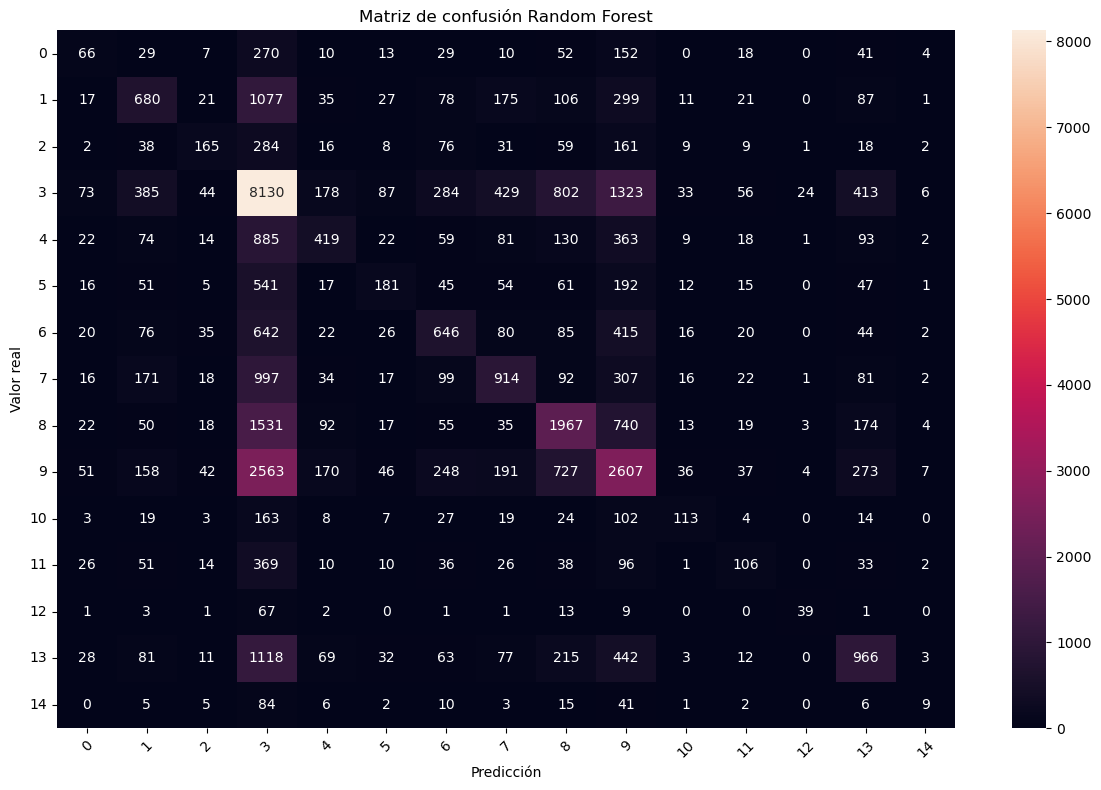

In [70]:
#Matriz de confusión random forest

y_pred_rf = pipeline_rf.predict(Xtest)

cm = confusion_matrix(ytest, y_pred_rf)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,          # muestra los valores dentro de cada celda
    fmt="d",            # formato entero
    cbar=True           # barra de color
)
plt.title("Matriz de confusión Random Forest")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

KNN

In [71]:
from sklearn.neighbors import KNeighborsClassifier

In [72]:
knn = KNeighborsClassifier()

In [73]:
preprocess_knn = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais"]),
    ("num_procesadas", pipeline_num, ["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion"])])

In [74]:
pipeline_knn = Pipeline(steps=[('preprocesamiento', preprocess_knn),
                              ('modelo', knn)])

In [75]:
pipeline_knn.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['pais']),
                                                 ('num_procesadas',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['views', 'likes', 'dislikes',
                                                   'comment_count',
                                                   'dias_desde_publicacion'])])),
                ('modelo', KNeighborsClassifier())])

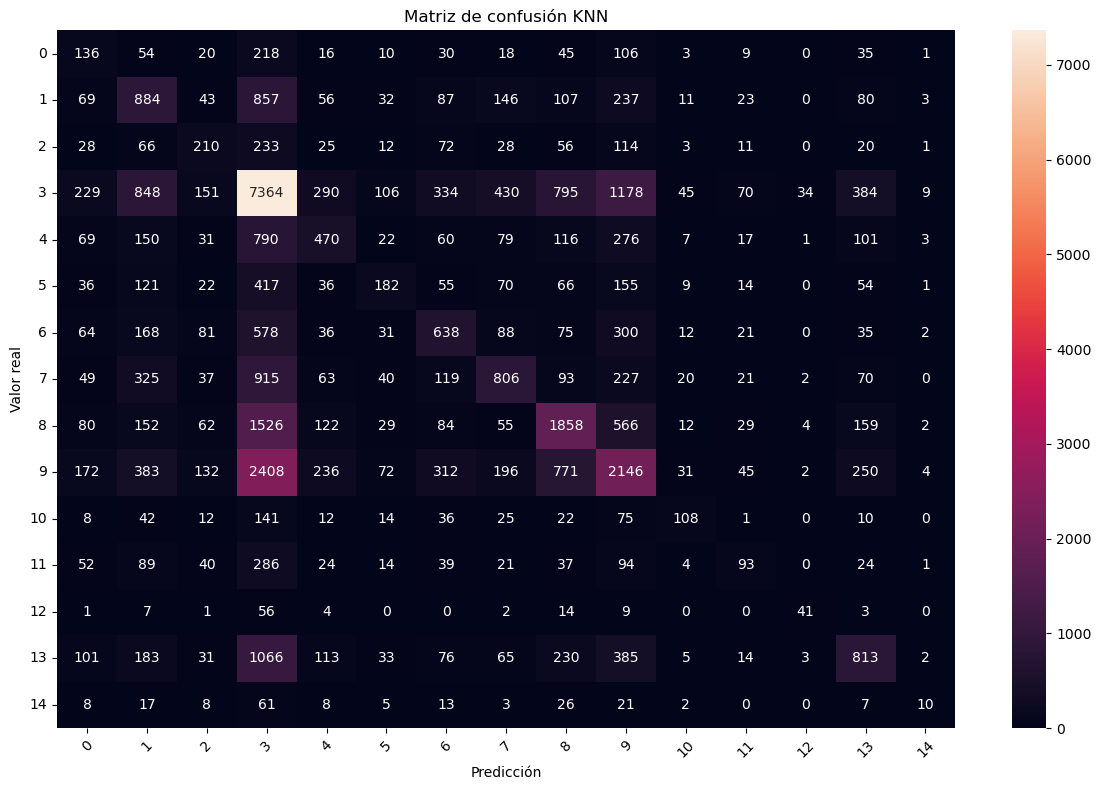

In [76]:
#Matriz de confusión KNN

y_pred_knn = pipeline_knn.predict(Xtest)

cm = confusion_matrix(ytest, y_pred_knn)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,          # muestra los valores dentro de cada celda
    fmt="d",            # formato entero
    cbar=True           # barra de color
)
plt.title("Matriz de confusión KNN")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Vemos que aquí el modelo acierta más y aunque sigue teniendo la misma tendencia, los datos de aciertos en distintas variables están más repartidos. Hay un claro desbalanceo de clases.

SVM

In [77]:
from sklearn.svm import SVC

In [78]:
svm = SVC(kernel='rbf', cache_size=1000, tol=1e-1, shrinking=True, max_iter=1000)  
# Tras varios intentos sabiendo que este no sería el modelo, optimizamos para que lo ejecute y se procese rápido

In [79]:
preprocess_svm = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais"]),
    ("num_procesadas", pipeline_num, ["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion"])])

In [80]:
pipeline_svm = Pipeline(steps=[("preprocesamiento", preprocess_svm),
                              ("modelo", svm)])

In [81]:
pipeline_svm.fit(Xtrain, ytrain)

c:\Users\luci_\anaconda3\Lib\site-packages\sklearn\svm\_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['pais']),
                                                 ('num_procesadas',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['views', 'likes', 'dislikes',
                                                   'comment_count',
                                                   'dias_desde_publicacion'])])),
                ('modelo', SVC(cache_size=1000, max_iter=1000, tol=0.1))])

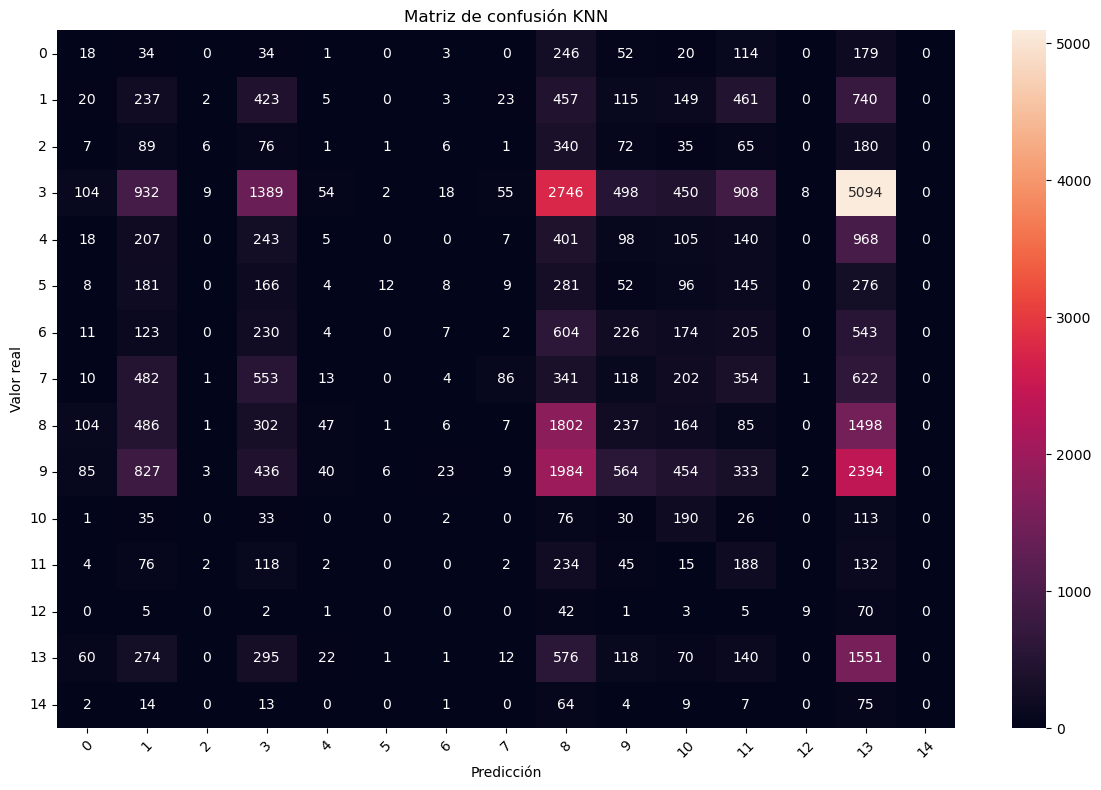

In [82]:
#Matriz de confusión SVM

y_pred_svm = pipeline_svm.predict(Xtest)
cm = confusion_matrix(ytest, y_pred_svm)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,          # muestra los valores dentro de cada celda
    fmt="d",            # formato entero
    cbar=True           # barra de color
)
plt.title("Matriz de confusión KNN")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Vistas las matrices de confusión, procedemos a comparar todas las métricas para ver los valores más altos.

In [83]:
clasification = {
    "Modelo": ["Regresión Logística", "Random Forest", "KNN", "SVM"],
    "Accuracy": [
        classification_report(ytest, y_pred_lr,zero_division=0, output_dict=True)["accuracy"],
        classification_report(ytest, y_pred_rf,zero_division=0, output_dict=True)["accuracy"],
        classification_report(ytest, y_pred_knn,zero_division=0, output_dict=True)["accuracy"],
        classification_report(ytest, y_pred_svm, zero_division=0,output_dict=True)["accuracy"]
    ],
    "F1 Macro": [
        classification_report(ytest, y_pred_lr,zero_division=0, output_dict=True)["macro avg"]["f1-score"],
        classification_report(ytest, y_pred_rf,zero_division=0, output_dict=True)["macro avg"]["f1-score"],
        classification_report(ytest, y_pred_knn,zero_division=0, output_dict=True)["macro avg"]["f1-score"],
        classification_report(ytest, y_pred_svm,zero_division=0, output_dict=True)["macro avg"]["f1-score"]
    ],
    "F1 Weighted": [
        classification_report(ytest, y_pred_lr,zero_division=0, output_dict=True)["weighted avg"]["f1-score"],
        classification_report(ytest, y_pred_rf,zero_division=0, output_dict=True)["weighted avg"]["f1-score"],
        classification_report(ytest, y_pred_knn,zero_division=0, output_dict=True)["weighted avg"]["f1-score"],
        classification_report(ytest, y_pred_svm,zero_division=0, output_dict=True)["weighted avg"]["f1-score"]
    ],
    "Recall Macro": [
        classification_report(ytest, y_pred_lr,zero_division=0, output_dict=True)["macro avg"]["recall"],
        classification_report(ytest, y_pred_rf, zero_division=0,output_dict=True)["macro avg"]["recall"],
        classification_report(ytest, y_pred_knn,zero_division=0, output_dict=True)["macro avg"]["recall"],
        classification_report(ytest, y_pred_svm, zero_division=0,output_dict=True)["macro avg"]["recall"]
    ],
    "Precision Macro": [
        classification_report(ytest, y_pred_lr, zero_division=0,output_dict=True)["macro avg"]["precision"],
        classification_report(ytest, y_pred_rf,zero_division=0, output_dict=True)["macro avg"]["precision"],
        classification_report(ytest, y_pred_knn,zero_division=0, output_dict=True)["macro avg"]["precision"],
        classification_report(ytest, y_pred_svm,zero_division=0, output_dict=True)["macro avg"]["precision"]
    ]
}

df_clasification = pd.DataFrame(clasification)

metricas = ["Accuracy", "F1 Macro", "F1 Weighted", "Recall Macro", "Precision Macro"]

df_clasification = df_clasification.sort_values(by="F1 Macro", ascending=False)

tabla_clasification = df_clasification.style#usamos esto para personalizar la tabla

for col in metricas:
    tabla_clasification = tabla_clasification.highlight_max(subset=[col], props="font-weight: bold; font-size: 16px;")

tabla_clasification.hide()#ocultamos el indice

Modelo,Accuracy,F1 Macro,F1 Weighted,Recall Macro,Precision Macro
Random Forest,0.409841,0.296255,0.390775,0.262883,0.374048
KNN,0.379744,0.281494,0.368319,0.263229,0.330483
Regresión Logística,0.332080,0.090639,0.242494,0.102518,0.132705
SVM,0.146124,0.084028,0.125399,0.127226,0.189490


Elegimos el modelo Random Forest. Procedemos a optimizarlo con RandomizedSearchCV en lugar de GridSearchCV, ya que al intentarlo con Grid el coste computacional era enorme.

In [84]:
from sklearn.model_selection import RandomizedSearchCV #No utilizamos Grid ya que al intentarlos el coste computacional era enorme 
from sklearn.metrics import f1_score, classification_report 

In [85]:
param_dist = {
    "modelo__n_estimators": [100, 150],
    "modelo__criterion": ["gini", "entropy"],#no utilizamos log_loss porque se basan en la misma medida
    "modelo__max_depth": [12, 20, None],
    "modelo__min_samples_split": [2, 5, 10],
    "modelo__min_samples_leaf": [1, 2, 4],
    "modelo__max_features": ["sqrt", "log2", 0.5],
    "modelo__class_weight": [None, "balanced", "balanced_subsample"],
    "modelo__bootstrap": [True],
    "modelo__max_samples": [0.7, 0.8]
}

grid_search_rf = RandomizedSearchCV(
    estimator=pipeline_rf,         
    param_distributions=param_dist,
    n_iter=12,
    scoring="f1_macro",
    n_jobs=1,
    pre_dispatch="n_jobs",
    verbose=1,
    cv=2,
    random_state=42,
    refit=True
)

grid_search_rf.fit(Xtrain, ytrain)

rf_optimo = grid_search_rf.best_estimator_

print("Best parameters:", grid_search_rf.best_params_)
print("Best CV f1_macro:", grid_search_rf.best_score_)

y_pred_train = rf_optimo.predict(Xtrain)
y_pred_test = rf_optimo.predict(Xtest)

print("\nTrain f1_macro:", f1_score(ytrain, y_pred_train, average="macro"))
print(classification_report(ytrain, y_pred_train))

print("\nTest f1_macro:", f1_score(ytest, y_pred_test, average="macro"))
print(classification_report(ytest, y_pred_test))


Fitting 2 folds for each of 12 candidates, totalling 24 fits
Best parameters: {'modelo__n_estimators': 150, 'modelo__min_samples_split': 2, 'modelo__min_samples_leaf': 1, 'modelo__max_samples': 0.8, 'modelo__max_features': 'log2', 'modelo__max_depth': 20, 'modelo__criterion': 'gini', 'modelo__class_weight': 'balanced_subsample', 'modelo__bootstrap': True}
Best CV f1_macro: 0.307129808628421

Train f1_macro: 0.8225185134191485
              precision    recall  f1-score   support

           0       0.47      0.98      0.63      2805
           1       0.84      0.89      0.86     10542
           2       0.74      0.95      0.83      3517
           3       0.94      0.79      0.86     49065
           4       0.78      0.88      0.83      8769
           5       0.83      0.93      0.88      4952
           6       0.63      0.92      0.75      8516
           7       0.92      0.87      0.89     11146
           8       0.82      0.87      0.85     18961
           9       0.94      

El modelo encuentra más categorías pero sus predicciones son menos fiables. El Randomized mejoró levemente el modelo.

Reto opcional para subir nota: Crear un algoritmo de clasificación que intente averiguar lo mejor posible si los comentarios o los ratings estarán deshabilitados por parte del creador del vídeo en base al resto de la información. Al ser una clasificación altamente desbalanceada se valorará no solo obtener una alta precisión, sino también estudiar en una matriz de confusión si se sega excesivamente hacia la clase mayoritaria y en el caso de que ocurra intentar mitigar este hecho.

**Predecir el número de likes**

**Encontrar grupos en los vídeos mediante diversas técnicas de clusterización**

**Crear un recomendador**

""title: El título del video en formato de texto original libre (tal y como lo escribió el creador, incluyendo emojis, mayúsculas y caracteres especiales). 

channel_title: El nombre original del canal de YouTube que subió el video.  

category_id: El identificador de la categoría asignada al video. Actualizado más arriba por el país en cuestión. 

tags: Las palabras clave asociadas al video. 

views: La cantidad de reproducciones acumuladas que registraba el video en ese día específico en que apareció en tendencias.  

likes: La cantidad de votos "Me gusta" acumulados que tenía el video en ese día específico.  

dislikes: La cantidad de votos "No me gusta" acumulados que tenía el video en ese día específico.  

comment_count: El número de comentarios totales escritos por los usuarios en ese día específico.  

comments_disabled: Un interruptor lógico (True/False) que indica si el canal tenía los comentarios desactivados en ese momento.  

ratings_disabled: Un interruptor lógico (True/False) que indica si el canal tenía ocultos los contadores de likes/dislikes en ese momento.  

video_error_or_removed: Un interruptor lógico (True/False) que indica si el video fue borrado o tuvo un error mientras estaba en la lista de tendencias.  

description: El texto explicativo original largo que el creador colocó en la caja de descripción del video. 

pais: El país donde se obtuvo el dato.

Estos son los items que tendremos que predecir:  
1.Prediga la categoría del vídeo  
2.Predecir el número de likes  
3.Encontrar grupos en los vídeos mediante diversas técnicas de clusterización  
4.Crear un recomendador

[('title', 'string'), 
 ('channel_title', 'string'),
 ('pais', 'string'),
 ('views', 'int'),
 ('tags', 'string'),
 ('likes', 'int'),
 ('dislikes', 'int'),
 ('comment_count', 'int'),
 ('comments_disabled', 'boolean'),
 ('ratings_disabled', 'boolean'),
 ('video_error_or_removed', 'boolean'),
 ('description', 'string'),
 ('category', 'string'),
 ('month_trending', 'int'),
 ('month_publish', 'int')]"""
 • ¿Estás clasificando categorías? Usa Regresión Logística, Árboles de decisión, KNN o SVM.
• ¿Estás prediciendo un número? Usa Regresión Lineal o Árboles de decisión (Regresores).
• ¿Tus datos no tienen etiquetas (no sabes la respuesta)? Usa Clustering o Reducción de dimensionalidad.